# 09 · Inventory optimisation with OR-Tools
For each item-store and each weekly replenishment cycle we choose an order quantity that minimises
**expected holding + stockout cost** over demand scenarios drawn from the quantile forecasts, subject to a
**purchasing budget** (and optionally shelf capacity). We then replay the 4 test weeks with *real* demand and
compare policies:

| Policy | Idea |
|---|---|
| A. Last week's sales | what many stores do today |
| B. Forecast mean | order the LightGBM point forecast |
| C. Optimised | OR-Tools, unconstrained budget |
| D. Optimised, same budget as B | same money as B, smarter allocation |

Cost assumptions (documented in `src/config.py`): unit cost = 70% of price; holding = 2% of unit cost per cycle;
stockout = lost margin + 0.5×price goodwill penalty. M5 has no cost data, so these are explicit assumptions.

In [1]:
import sys; sys.path.insert(0, "..")
import warnings, logging; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

import time
from src.optimizer import sample_demand, optimize_orders, realised_cost, cost_params, round_orders
from src.features import time_split
feat = pd.read_parquet(PROC_DIR / "features.parquet", columns=["id", "date", "sales", "sell_price", "cat_id"])
qf = pd.read_parquet(OUT_DIR / "forecast_quantiles.parquet")
pt = pd.read_parquet(OUT_DIR / "pred_point.parquet")[["id", "date", "pred_lgbm"]]
qcols = [f"q{int(q*100):02d}" for q in QUANTILES]
ids = sorted(qf.id.unique()); dates = sorted(qf.date.unique())
weeks = [dates[i:i + CYCLE_DAYS] for i in range(0, len(dates), CYCLE_DAYS)]
test_start = dates[0]
hist = feat[feat.date < test_start].pivot(index="date", columns="id", values="sales")[ids]
price_all = feat[feat.date >= test_start].merge(qf[["id", "date"]], on=["id", "date"])
N_SCEN = 40
cat = feat.drop_duplicates("id").set_index("id")["cat_id"].astype(str).loc[ids].values

In [2]:
results, order_rows, solve_times = [], [], []
prev_week_actual = hist.iloc[-CYCLE_DAYS:].sum().values          # for policy A in week 0
for k, wk in enumerate(weeks):
    wq = qf[qf.date.isin(wk)].sort_values(["id", "date"])
    Q = wq[qcols].values.reshape(len(ids), len(wk), len(qcols))
    actual = wq.pivot(index="id", columns="date", values="sales").loc[ids].sum(axis=1).values
    price = price_all[price_all.date.isin(wk)].groupby("id")["sell_price"].mean().loc[ids].values
    fmean = pt[pt.date.isin(wk)].groupby("id")["pred_lgbm"].sum().loc[ids].values
    scen = sample_demand(Q, n_scen=N_SCEN, seed=SEED + k)
    unit_cost, _, _ = cost_params(price, cat)

    q_a = np.round(prev_week_actual)
    q_b = np.round(fmean)
    t0 = time.time(); q_c, st_c = optimize_orders(scen, price, cat=cat); solve_times.append(time.time() - t0)
    budget_b = float((unit_cost * q_b).sum())
    t0 = time.time(); q_d, st_d = optimize_orders(scen, price, budget=budget_b, cat=cat); solve_times.append(time.time() - t0)
    q_c, q_d = round_orders(q_c, price), round_orders(q_d, price, budget=budget_b)   # whole units, budget kept
    assert (unit_cost * q_d).sum() <= budget_b + 1e-6, "budget violated"
    for name, q in [("A last-week sales", q_a), ("B forecast mean", q_b), ("C optimised", q_c), ("D optimised, B's budget", q_d)]:
        results.append({"week": k + 1, "policy": name, **realised_cost(q, actual, price, cat=cat)})
    order_rows.append(pd.DataFrame({"week": k + 1, "id": ids, "price": price, "forecast_mean": fmean,
        "order_last_week": q_a, "order_forecast_mean": q_b, "order_optimised": q_c,
        "order_optimised_budget": q_d, "actual_demand": actual}))
    prev_week_actual = actual
    print(f"week {k+1}: solver {st_c}/{st_d}, {solve_times[-2]:.1f}s + {solve_times[-1]:.1f}s")

res = pd.DataFrame(results)
summary = (res.groupby("policy")[["holding_cost", "stockout_cost", "total_cost", "purchase_spend", "units_short", "units_left"]].sum()
           .join(res.groupby("policy")["fill_rate"].mean()))
base_cost = summary.loc["B forecast mean", "total_cost"]
summary["cost_vs_B_%"] = (summary["total_cost"] / base_cost - 1) * 100
summary = summary.round(2); summary.to_csv(OUT_DIR / "cost_comparison.csv")
pd.concat(order_rows).to_parquet(OUT_DIR / "orders.parquet")
res.to_csv(OUT_DIR / "cost_by_week.csv", index=False)
summary

week 1: solver OPTIMAL/OPTIMAL, 1.0s + 1.8s


week 2: solver OPTIMAL/OPTIMAL, 0.9s + 2.0s


week 3: solver OPTIMAL/OPTIMAL, 1.0s + 1.9s


week 4: solver OPTIMAL/OPTIMAL, 0.9s + 1.9s


,holding_cost,stockout_cost,total_cost,purchase_spend,units_short,units_left,fill_rate,cost_vs_B_%
policy,,,,,,,,
A last-week sales,1871.95,16102.47,17974.42,73426.70,5678.0,5783.0,0.81,32.36
B forecast mean,1191.25,12388.75,13579.99,71171.35,4400.0,3437.0,0.85,0.00
C optimised,3220.50,2828.47,6048.98,102616.45,939.0,13109.0,0.97,-55.46
"D optimised, B's budget",1079.76,12825.50,13905.26,71159.80,4558.0,3598.0,0.85,2.40


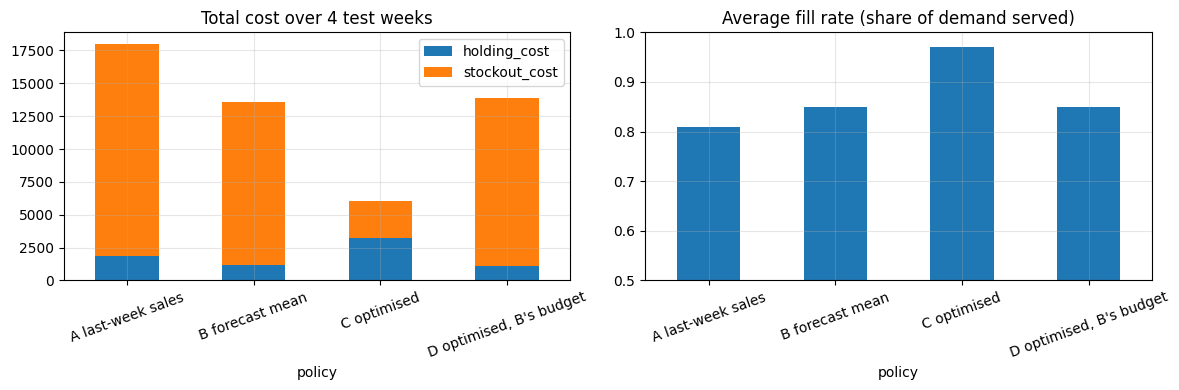

Mean OR-Tools solve time: 1.4s for 600 series x 40 scenarios


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
summary[["holding_cost", "stockout_cost"]].plot.bar(stacked=True, ax=ax[0], title="Total cost over 4 test weeks"); ax[0].tick_params(axis="x", rotation=20)
summary["fill_rate"].plot.bar(ax=ax[1], title="Average fill rate (share of demand served)", ylim=(0.5, 1)); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG_DIR / "09_policy_costs.png", dpi=120); plt.show()
print(f"Mean OR-Tools solve time: {np.mean(solve_times):.1f}s for {len(ids)} series x {N_SCEN} scenarios")

**How to read it:** the optimiser deliberately stocks *more* of items where stockouts are expensive and *less* where
holding is cheap relative to uncertainty; D shows the gain from smarter allocation at the **same spend** as B.
Re-run with different cost assumptions to show sensitivity in the presentation.